# Задание 3. Модульные ёмкости и маршрутизация (Pyomo)

Формулировка **«адрес назначения — канал»** (destination-link).

Ниже — **математическая постановка**, по которой объясняется решение.  
Дальше в ноутбуке — реализация той же модели на Pyomo.

---

## Математическая формализация

### 1. Дано

Ориентированный граф сети $G = (N, E)$:

| Обозначение | Смысл |
|-------------|--------|
| $N$ | множество узлов |
| $E$ | множество каналов (направленных дуг) |
| $h_{nt}$ | трафик из узла $n$ к назначению $t$ (считаем $h_{tt} = 0$) |
| $C > 0$ | ёмкость **одного** модуля |
| $d_e > 0$ | длина канала $e$ (км) |
| $\delta^+(n)$ | исходящие каналы из $n$ |
| $\delta^-(n)$ | входящие каналы в $n$ |

Оборудование пересылает трафик **по адресу назначения** $t$, поэтому потоки агрегируются по $t$, а не по отдельным заявкам «источник–сток».

### 2. Переменные решения

Число модулей на канале $e$:

$$
a_e \in \{0, 1, 2, \ldots\}, \quad e \in E
$$

Объём трафика к назначению $t$, идущий по каналу $e$:

$$
x_{te} \ge 0, \quad t \in N,\ e \in E
$$

### 3. Критерии (решаются отдельно)

**Критерий $F_1$** — минимум числа модулей:

$$
F_1 = \min_{a,x} \sum_{e \in E} a_e
$$

**Критерий $F_2$** — минимум стоимости с учётом длины линий (модуль·км):

$$
F_2 = \min_{a,x} \sum_{e \in E} d_e \, a_e
$$

Это две самостоятельные задачи с **одной и той же** допустимой областью, а не одна свёртка двух целей.

### 4. Ограничения

**Баланс потока** (destination-link) для всех $n, t \in N$.

Если $n \neq t$ (узел порождает / транзитит трафик к $t$):

$$
\sum_{e \in \delta^+(n)} x_{te} - \sum_{e \in \delta^-(n)} x_{te} = h_{nt}
$$

Если $n = t$ (назначение поглощает весь трафик к $t$):

$$
\sum_{e \in \delta^+(t)} x_{te} - \sum_{e \in \delta^-(t)} x_{te} = -\sum_{s \neq t} h_{st}
$$

**Ёмкость канала** для всех $e \in E$:

$$
\sum_{t \in N} x_{te} \le C \, a_e
$$

На канале суммируются потоки ко **всем** назначениям; модули покупаются на канал целиком.

### 5. Тип задачи и релаксация

Задача относится к **MILO / MILP**:

- цель и ограничения линейны;
- $a_e$ — целые;
- $x_{te}$ — непрерывные.

Нельзя решить непрерывную модель и округлить $a_e$: округление не гарантирует допустимость и оптимальность. Решаем MILO-солвером (HiGHS через Pyomo).

**Линейная релаксация:** заменить $a_e \in \mathbb{Z}_{\ge 0}$ на $a_e \ge 0$.  
Для минимизации $z_{\mathrm{ЛО}} \le z_{\mathrm{MILO}}$ — это нижняя оценка, а не план установки оборудования.

### 6. Доли пересылки (после решения)

$$
f_{te} = \frac{x_{te}}{h_{a(e)t} + \sum_{e' \in \delta^-(a(e))} x_{te'}}
$$

где $a(e)$ — начало канала $e$. Если знаменатель равен нулю, правило маршрутизации для этой пары не определено текущей матрицей $h$.

### 7. Что показывает код ниже

1. Строит модель Pyomo ровно под формулы выше.  
2. Решает $F_1$ и $F_2$ отдельно.  
3. Считает ЛО-релаксацию и проверяет $z_{\mathrm{ЛО}} \le z_{\mathrm{MILO}}$.  
4. Выводит загрузку каналов, доли $f_{te}$ и рисунок сети.


## 1. Импорты и решатель

Нужны пакеты: `pyomo`, `highspy`, `pandas`, `networkx`, `matplotlib`.

Решатель: `SolverFactory('appsi_highs')` — для непрерывных задач решает ЛО, для целых $a_e$ — MILO.


In [1]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib
import matplotlib.pyplot as plt
import pyomo.environ as pyo

# В Jupyter нужен интерактивный/inline backend, иначе plt.show() ругается на Agg.
try:
    from IPython import get_ipython
    ip = get_ipython()
    if ip is not None:
        ip.run_line_magic('matplotlib', 'inline')
except Exception:
    pass

solver = pyo.SolverFactory('appsi_highs')
assert solver.available(exception_flag=False), 'Установите highspy: %pip install highspy'


## 2. Данные (демо-сеть)

В условии числовой пример не зафиксирован — берём небольшой ориентированный граф.  
Матрица $h$ задаётся словарём `(источник, назначение) -> объём`, длины $d_e$ — словарём каналов.


In [2]:
data = {
    'nodes': ['A', 'B', 'C', 'D', 'E'],
    'links': {  # канал -> длина d_e (км)
        ('A', 'D'): 12, ('A', 'B'): 2, ('B', 'C'): 2, ('C', 'D'): 2,
        ('B', 'D'): 9, ('E', 'D'): 10, ('E', 'C'): 2, ('A', 'E'): 4,
    },
    'demands': {  # (источник, назначение) -> объём h
        ('A', 'D'): 8, ('E', 'D'): 6, ('B', 'D'): 3,
    },
    'C': 5.0,  # ёмкость одного модуля
}

# Проверка: для каждого спроса есть путь
G = nx.DiGraph()
G.add_nodes_from(data['nodes'])
G.add_edges_from(data['links'])
for s, t in data['demands']:
    assert nx.has_path(G, s, t), (s, t)

pd.DataFrame(
    [(s, t, h) for (s, t), h in data['demands'].items()],
    columns=['source', 'destination', 'traffic'],
)


source,destination,traffic
A,D,8
E,D,6
B,D,3


## 3. Модель Pyomo = формулы из формализации

Соответствие:

| Математика | Код |
|------------|-----|
| $a_e \in \mathbb{Z}_{\ge 0}$ | `Var(..., NonNegativeIntegers)` |
| $x_{te} \ge 0$ | `Var(N, E, NonNegativeReals)` → `x[t,u,v]` |
| баланс $\forall t, n$ | `Constraint(N, N, rule=balance_rule)` |
| $\sum_t x_{te} \le C a_e$ | `Constraint(E, rule=...)` |
| $F_1 = \sum a_e$ | `mode='modules'` |
| $F_2 = \sum d_e a_e$ | `mode='distance'` |
| релаксация | `relax=True` → у $a_e$ домен `NonNegativeReals` |


In [3]:
def build_model(d, mode='modules', relax=False):
    # mode: 'modules' -> F1, 'distance' -> F2; relax=True -> дробные a_e (ЛО)
    m = pyo.ConcreteModel('DestinationLink')
    m.N = pyo.Set(initialize=d['nodes'], ordered=True)
    m.E = pyo.Set(initialize=list(d['links']), dimen=2, ordered=True)
    m.C = pyo.Param(initialize=d['C'])
    m.length = pyo.Param(m.E, initialize=d['links'])
    m.h = pyo.Param(m.N, m.N, initialize=d['demands'], default=0)

    m.a = pyo.Var(
        m.E,
        domain=pyo.NonNegativeReals if relax else pyo.NonNegativeIntegers,
    )
    m.x = pyo.Var(m.N, m.E, domain=pyo.NonNegativeReals)

    out = {n: [e for e in m.E if e[0] == n] for n in m.N}
    inn = {n: [e for e in m.E if e[1] == n] for n in m.N}

    def balance_rule(m, t, n):
        rhs = m.h[n, t] if n != t else -sum(m.h[s, t] for s in m.N if s != t)
        return (
            sum(m.x[t, u, v] for u, v in out[n])
            - sum(m.x[t, u, v] for u, v in inn[n])
            == rhs
        )

    m.balance = pyo.Constraint(m.N, m.N, rule=balance_rule)
    m.capacity = pyo.Constraint(
        m.E,
        rule=lambda m, u, v: sum(m.x[t, u, v] for t in m.N) <= m.C * m.a[u, v],
    )

    m.module_count = pyo.Expression(expr=sum(m.a[e] for e in m.E))
    m.distance_cost = pyo.Expression(expr=sum(m.length[e] * m.a[e] for e in m.E))
    m.obj = pyo.Objective(
        expr=m.module_count if mode == 'modules' else m.distance_cost,
        sense=pyo.minimize,
    )
    return m


def solve(m):
    res = solver.solve(m)
    assert res.solver.termination_condition == pyo.TerminationCondition.optimal
    return m


def link_table(m):
    rows = []
    for u, v in m.E:
        a = max(0.0, round(pyo.value(m.a[u, v]), 10))
        flow = max(0.0, sum(pyo.value(m.x[t, u, v]) for t in m.N))
        cap = pyo.value(m.C) * a
        rows.append({
            'from': u, 'to': v, 'length': pyo.value(m.length[u, v]),
            'modules a_e': a, 'capacity': cap, 'flow': flow,
            'utilization': (flow / cap) if cap > 1e-9 else np.nan,
        })
    return pd.DataFrame(rows)


## 4. Критерий $F_1$: минимум числа модулей

Решаем MILO и отдельно ЛО-релаксацию (дробные $a_e$) — нижняя оценка.


In [4]:
m1 = solve(build_model(data, mode='modules'))
lp1 = solve(build_model(data, mode='modules', relax=True))

print('F1 (MILO):', pyo.value(m1.obj))
print('F1 (ЛО-релаксация):', pyo.value(lp1.obj))
print('Проверка нижней границы: ЛО <= MILO?', pyo.value(lp1.obj) <= pyo.value(m1.obj) + 1e-6)

display(link_table(m1).round(4))


F1 (MILO): 5.0
F1 (ЛО-релаксация): 3.4000000000000004
Проверка нижней границы: ЛО <= MILO? True


from,to,length,modules a_e,capacity,flow,utilization
A,D,12,2.0,10.0,8.0,0.8
A,B,2,0.0,0.0,0.0,NaN
B,C,2,0.0,0.0,0.0,NaN
C,D,2,0.0,0.0,0.0,NaN
B,D,9,1.0,5.0,3.0,0.6
E,D,10,2.0,10.0,6.0,0.6
E,C,2,0.0,0.0,0.0,NaN
A,E,4,0.0,0.0,0.0,NaN


## 5. Критерий $F_2$: минимум $\sum d_e a_e$

Та же допустимая область, другая целевая функция.


In [5]:
m2 = solve(build_model(data, mode='distance'))
lp2 = solve(build_model(data, mode='distance', relax=True))

print('F2 (MILO):', pyo.value(m2.obj))
print('F2 (ЛО-релаксация):', pyo.value(lp2.obj))
print('Проверка нижней границы: ЛО <= MILO?', pyo.value(lp2.obj) <= pyo.value(m2.obj) + 1e-6)

display(link_table(m2).round(4))


F2 (MILO): 22.0
F2 (ЛО-релаксация): 16.8
Проверка нижней границы: ЛО <= MILO? True


from,to,length,modules a_e,capacity,flow,utilization
A,D,12,0.0,0.0,0.0,NaN
A,B,2,2.0,10.0,8.0,0.8000
B,C,2,3.0,15.0,11.0,0.7333
C,D,2,4.0,20.0,17.0,0.8500
B,D,9,0.0,0.0,0.0,NaN
E,D,10,0.0,0.0,0.0,NaN
E,C,2,2.0,10.0,6.0,0.6000
A,E,4,0.0,0.0,0.0,NaN


## 6. Доли пересылки $f_{te}$

$$
f_{te} = \frac{x_{te}}{h_{a(e)t} + \sum_{e' \in \delta^-(a(e))} x_{te'}}
$$

Строим таблицу для решения критерия $F_1$.


In [6]:
def forwarding_table(m):
    rows = []
    for t in m.N:
        for n in m.N:
            if n == t:
                continue
            available = pyo.value(m.h[n, t]) + sum(
                pyo.value(m.x[t, u, v]) for u, v in m.E if v == n
            )
            for u, v in m.E:
                if u != n:
                    continue
                flow = pyo.value(m.x[t, u, v])
                frac = flow / available if available > 1e-9 else np.nan
                if flow > 1e-9 or (available > 1e-9 and not np.isnan(frac)):
                    rows.append({
                        'destination t': t, 'node': n, 'next': v,
                        'available': available, 'flow x': flow, 'fraction f': frac,
                    })
    return pd.DataFrame(rows)

display(forwarding_table(m1).round(4))


destination t,node,next,available,flow x,fraction f
D,A,D,8.0,8.0,1.0
D,A,B,8.0,-0.0,-0.0
D,A,E,8.0,0.0,0.0
D,B,C,3.0,0.0,0.0
D,B,D,3.0,3.0,1.0
D,E,D,6.0,6.0,1.0
D,E,C,6.0,0.0,0.0


## 7. Визуализация

Толщина ребра пропорциональна $a_e$, подпись: поток / ёмкость.


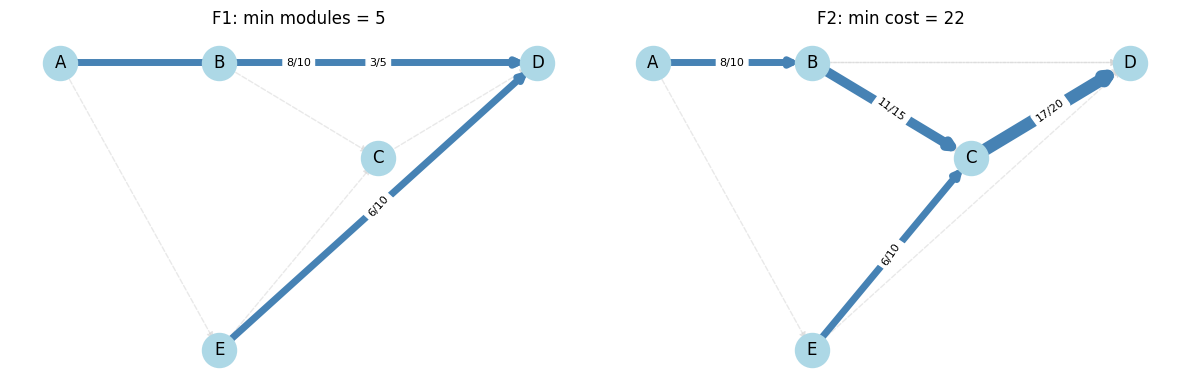

In [7]:
def draw(m, title, ax):
    pos = {'A': (0, 1), 'B': (1, 1), 'C': (2, 0.5), 'D': (3, 1), 'E': (1, -0.5)}
    H = nx.DiGraph()
    H.add_nodes_from(data['nodes'])
    H.add_edges_from(data['links'])
    tab = link_table(m)
    active = tab[tab['modules a_e'] > 1e-9]
    nx.draw_networkx_nodes(H, pos, ax=ax, node_color='lightblue', node_size=600)
    nx.draw_networkx_labels(H, pos, ax=ax)
    nx.draw_networkx_edges(H, pos, ax=ax, edge_color='lightgray', style='dashed', alpha=0.5)
    if not active.empty:
        edgelist = list(zip(active['from'], active['to']))
        widths = [1 + 2 * float(a) for a in active['modules a_e']]
        nx.draw_networkx_edges(H, pos, ax=ax, edgelist=edgelist, width=widths, edge_color='steelblue')
        labels = {
            (r['from'], r['to']): f"{r['flow']:g}/{r['capacity']:g}"
            for _, r in active.iterrows()
        }
        nx.draw_networkx_edge_labels(H, pos, ax=ax, edge_labels=labels, font_size=8)
    ax.set_title(title)
    ax.axis('off')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
draw(m1, f'F1: min modules = {pyo.value(m1.obj):g}', axes[0])
draw(m2, f'F2: min cost = {pyo.value(m2.obj):g}', axes[1])
plt.tight_layout()
plt.show()


## 8. Итог (для объяснения решения)

| Критерий | MILO | ЛО-релаксация | Смысл |
|----------|------|---------------|--------|
| $F_1 = \min \sum a_e$ | **5** | 3.4 | минимум модулей |
| $F_2 = \min \sum d_e a_e$ | **22** | 16.8 | минимум модуль·км |

Как объяснить устно:

1. Построили destination-link модель: переменные $a_e$, $x_{te}$, баланс + ёмкость.  
2. Это MILO, потому что модули целые — округление ЛО нельзя.  
3. Два критерия решили **отдельно** (два режима из задания).  
4. Релаксация даёт нижнюю границу ($3.4 < 5$, $16.8 < 22$), значит одного ЛО недостаточно.  
5. Сервис (UI/API) не делали — нужен только алгоритм на Pyomo.


In [8]:
assert abs(pyo.value(m1.obj) - 5) < 1e-6
assert abs(pyo.value(m2.obj) - 22) < 1e-6
assert abs(pyo.value(lp1.obj) - 3.4) < 1e-6
assert abs(pyo.value(lp2.obj) - 16.8) < 1e-6
print('OK: F1=5, F2=22, релаксации 3.4 и 16.8')


OK: F1=5, F2=22, релаксации 3.4 и 16.8
